<a href="https://colab.research.google.com/github/singh1742/India-vs-USA-Stock-Market-Analysis-2020-2025-/blob/main/IND_VS_USA_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


--- DATA CHECK ---
Rows, columns: (50, 11)
Missing values by column:
 Country     0
Exchange    0
Company     0
Ticker      0
Currency    0
2020        0
2021        0
2022        0
2023        0
2024        0
2025        0
dtype: int64

Number of companies by country:
 Country
India    25
USA      25
Name: count, dtype: int64


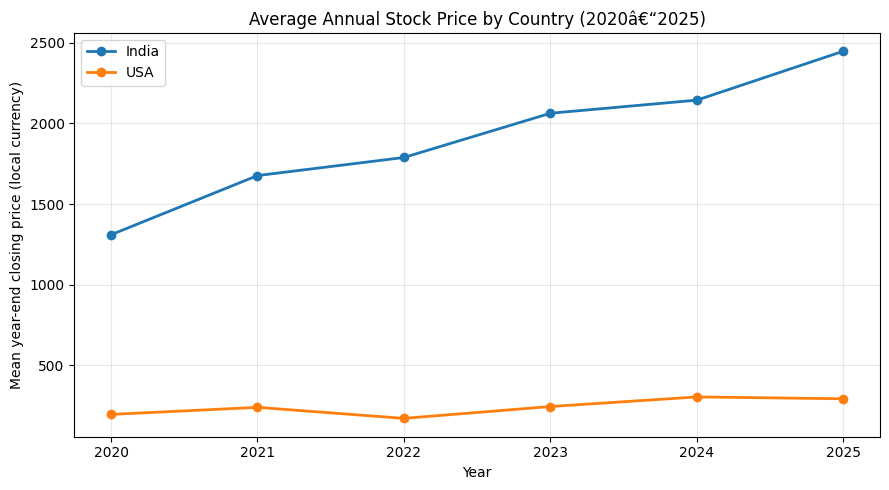

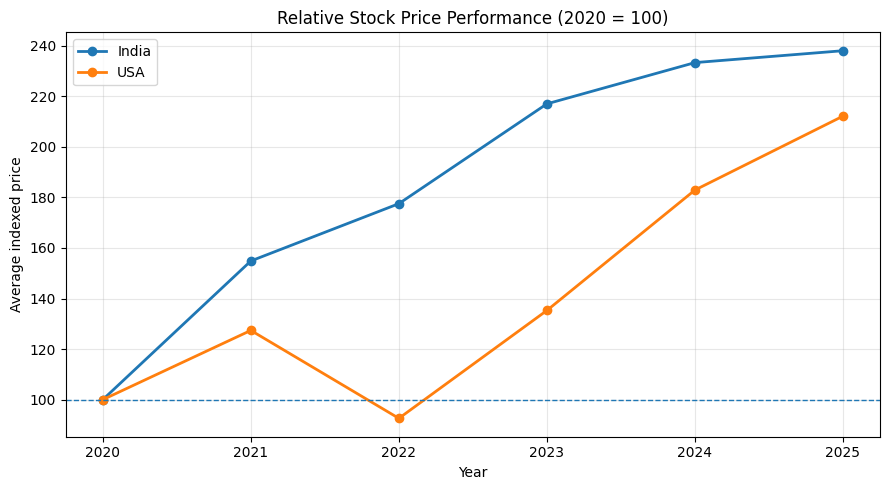

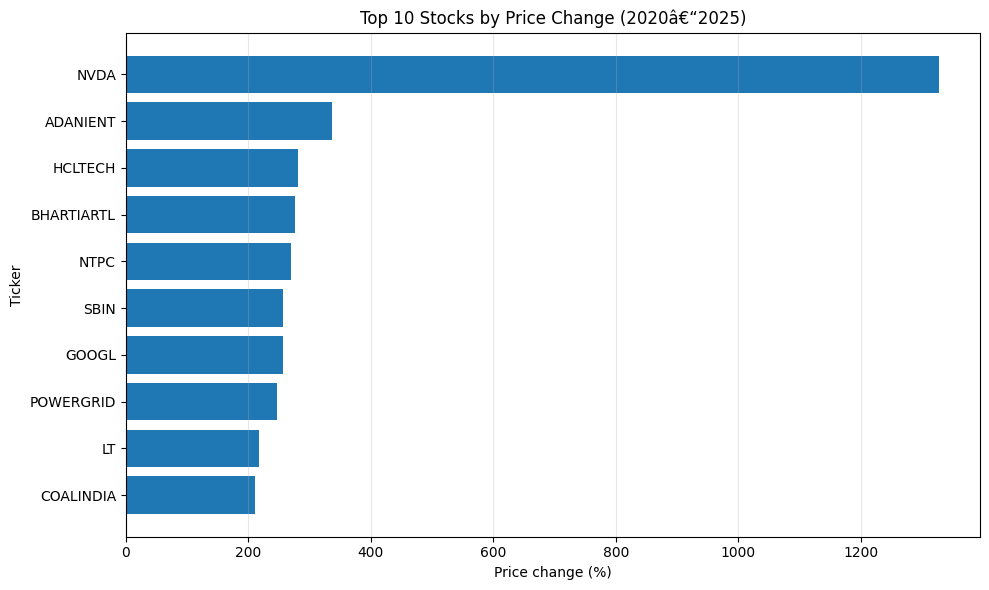

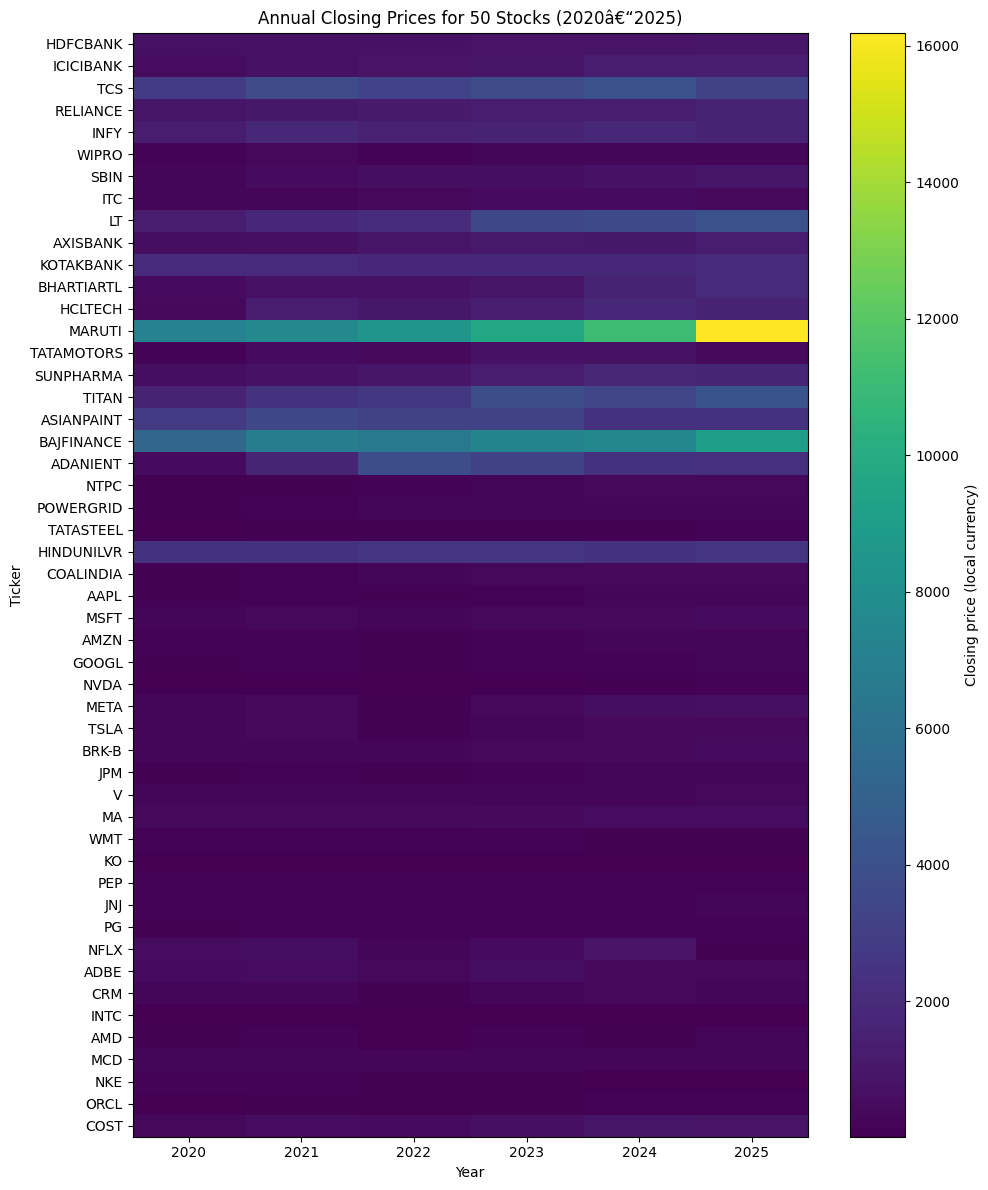


--- DESCRIPTIVE STATISTICS ---
         Count     Mean   Median  Std_Dev  Minimum   Maximum
Country                                                     
India      150  1904.79  1129.28  2365.37    63.05  16190.00
USA        150   241.89   183.58   175.44    13.06    917.77

Top 10 price changes (%):
 Country             Company     Ticker  Change_Percent
    USA              NVIDIA       NVDA         1328.02
  India   Adani Enterprises   ADANIENT          337.40
  India    HCL Technologies    HCLTECH          280.86
  India       Bharti Airtel BHARTIARTL          276.20
  India                NTPC       NTPC          268.91
  India State Bank of India       SBIN          257.23
    USA            Alphabet      GOOGL          256.75
  India          Power Grid  POWERGRID          247.02
  India     Larsen & Toubro         LT          217.14
  India          Coal India  COALINDIA          211.28

Average indexed price (2020 = 100):
 Country   India     USA
Year                   
2020 

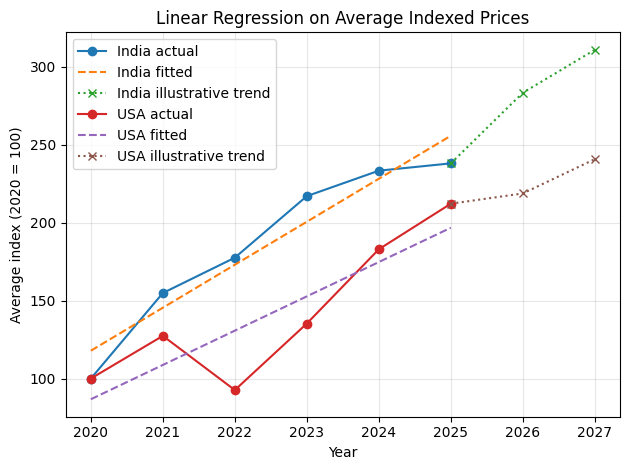

Country  Slope_index_points_per_year  Intercept  R_squared  Predicted_index_2026  Predicted_index_2027
  India                       27.567 -55568.135      0.928               283.262               310.830
    USA                       21.997 -44348.051      0.766               218.711               240.708

Completed. Check the files in: /content/India_USA_Analysis_Output


In [ ]:
"""
INDIA vs USA STOCK MARKET ANALYSIS (2020â€“2025)
Separate sections: visualization, descriptive statistics, and simple trend modeling.
Input workbook: India_USA_50_Stocks_2020_2025_Prices-1.xlsx
Required packages: pandas, openpyxl, matplotlib, numpy, scikit-learn
Run: python india_usa_analysis.py

Important:
- India stock prices are in INR; USA stock prices are in USD.
- Raw prices should NOT be compared directly across countries.
- The indexed-price chart rebases each stock to 100 in 2020 to compare relative change.
- This file uses annual values provided in the workbook; forecasts are illustrative only.
"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from pathlib import Path

FILE = "/content/India_USA_50_Stocks_2020_2025_Prices-1.xlsx"
OUT = Path("/content/India_USA_Analysis_Output")
OUT.mkdir(exist_ok=True, parents=True)

YEARS = [str(y) for y in range(2020, 2026)]
df = pd.read_excel(FILE, sheet_name="All 50 Stocks")
long_df = pd.read_excel(FILE, sheet_name="Long Format")

# ==========================================================
# CODE 1 â€“ DATA CHECK / PREPARATION
# ==========================================================
print("\n--- DATA CHECK ---")
print("Rows, columns:", df.shape)
print("Missing values by column:\n", df.isna().sum())
print("\nNumber of companies by country:\n", df["Country"].value_counts())

# Long-format data, one row per company per year
long_df["Year"] = long_df["Year"].astype(int)
long_df["Year_End_Close"] = pd.to_numeric(long_df["Year_End_Close"], errors="coerce")

# ==========================================================
# CODE 2 â€“ MATPLOTLIB VISUALIZATION
# ==========================================================
# 2A: Mean annual closing price by country (currencies differ, so use as within-country context only)
country_mean = long_df.groupby(["Country", "Year"])["Year_End_Close"].mean().reset_index()
plt.figure(figsize=(9, 5))
for country, part in country_mean.groupby("Country"):
    plt.plot(part["Year"], part["Year_End_Close"], marker="o", linewidth=2, label=country)
plt.title("Average Annual Stock Price by Country (2020â€“2025)")
plt.xlabel("Year")
plt.ylabel("Mean year-end closing price (local currency)")
plt.xticks(range(2020, 2026))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "01_average_price_by_country.png", dpi=200)
plt.show()

# 2B: Indexed price chart â€” each company's 2020 price = 100, then average by country
wide = df.set_index(["Country", "Company", "Ticker", "Currency"])[YEARS]
indexed = wide.div(wide["2020"], axis=0) * 100
indexed = indexed.reset_index()
indexed_long = indexed.melt(
    id_vars=["Country", "Company", "Ticker", "Currency"],
    value_vars=YEARS, var_name="Year", value_name="Index_2020_100"
)
indexed_long["Year"] = indexed_long["Year"].astype(int)
index_country = indexed_long.groupby(["Country", "Year"])["Index_2020_100"].mean().reset_index()
plt.figure(figsize=(9, 5))
for country, part in index_country.groupby("Country"):
    plt.plot(part["Year"], part["Index_2020_100"], marker="o", linewidth=2, label=country)
plt.axhline(100, linestyle="--", linewidth=1)
plt.title("Relative Stock Price Performance (2020 = 100)")
plt.xlabel("Year")
plt.ylabel("Average indexed price")
plt.xticks(range(2020, 2026))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "02_indexed_performance.png", dpi=200)
plt.show()

# 2C: Top 10 stocks by percentage price change, 2020â€“2025
ranking = df[["Country", "Company", "Ticker", "Currency", "2020", "2025"]].copy()
ranking["Change_Percent"] = (ranking["2025"] / ranking["2020"] - 1) * 100
top10 = ranking.sort_values("Change_Percent", ascending=False).head(10)
plt.figure(figsize=(10, 6))
plt.barh(top10["Ticker"][::-1], top10["Change_Percent"][::-1])
plt.title("Top 10 Stocks by Price Change (2020â€“2025)")
plt.xlabel("Price change (%)")
plt.ylabel("Ticker")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "03_top10_price_change.png", dpi=200)
plt.show()

# 2D: Annual stock price heatmap (all 50 companies)
heat = df.set_index("Ticker")[YEARS]
fig, ax = plt.subplots(figsize=(10, 12))
im = ax.imshow(heat.values, aspect="auto")
ax.set_title("Annual Closing Prices for 50 Stocks (2020â€“2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Ticker")
ax.set_xticks(range(len(YEARS)), YEARS)
ax.set_yticks(range(len(heat.index)), heat.index)
fig.colorbar(im, ax=ax, label="Closing price (local currency)")
plt.tight_layout()
plt.savefig(OUT / "04_stock_price_heatmap.png", dpi=200)
plt.show()

# ==========================================================
# CODE 3 â€“ DESCRIPTIVE STATISTICS
# ==========================================================
print("\n--- DESCRIPTIVE STATISTICS ---")
# Summary statistics for the annual price values, grouped by country
stats = long_df.groupby("Country")["Year_End_Close"].agg(
    Count="count", Mean="mean", Median="median", Std_Dev="std",
    Minimum="min", Maximum="max"
).round(2)
print(stats)
stats.to_csv(OUT / "descriptive_statistics_by_country.csv")

# Percentage price changes by company (not total return; dividends/splits may not be reflected)
ranking.to_csv(OUT / "stock_price_change_2020_2025.csv", index=False)
print("\nTop 10 price changes (%):\n", top10[["Country", "Company", "Ticker", "Change_Percent"]].round(2).to_string(index=False))

# Country-level mean indexed values and yearly changes
index_summary = index_country.pivot(index="Year", columns="Country", values="Index_2020_100").round(2)
print("\nAverage indexed price (2020 = 100):\n", index_summary)
index_summary.to_csv(OUT / "average_indexed_performance.csv")

# ==========================================================
# CODE 4 â€“ SIMPLE LINEAR REGRESSION MODEL
# ==========================================================
# Fit one linear trend per country on the average indexed series.
# This is a basic educational trend model, not investment advice.
print("\n--- LINEAR REGRESSION TREND MODEL ---")
model_results = []
future_years = np.array([2026, 2027]).reshape(-1, 1)
for country, part in index_country.groupby("Country"):
    X = part[["Year"]].values
    y = part["Index_2020_100"].values
    model = LinearRegression()
    model.fit(X, y)
    fitted = model.predict(X)
    r2 = model.score(X, y)
    future_pred = model.predict(future_years)
    model_results.append({
        "Country": country,
        "Slope_index_points_per_year": float(model.coef_[0]),
        "Intercept": float(model.intercept_),
        "R_squared": float(r2),
        "Predicted_index_2026": float(future_pred[0]),
        "Predicted_index_2027": float(future_pred[1])
    })
    plt.plot(part["Year"], y, marker="o", label=f"{country} actual")
    plt.plot(part["Year"], fitted, linestyle="--", label=f"{country} fitted")
    plt.plot([2025, 2026, 2027], [y[-1], future_pred[0], future_pred[1]], marker="x", linestyle=":", label=f"{country} illustrative trend")
plt.title("Linear Regression on Average Indexed Prices")
plt.xlabel("Year")
plt.ylabel("Average index (2020 = 100)")
plt.xticks(range(2020, 2028))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "05_linear_regression_trend.png", dpi=200)
plt.show()

model_df = pd.DataFrame(model_results).round(3)
print(model_df.to_string(index=False))
model_df.to_csv(OUT / "linear_regression_model_results.csv", index=False)

print("\nCompleted. Check the files in:", OUT.resolve())

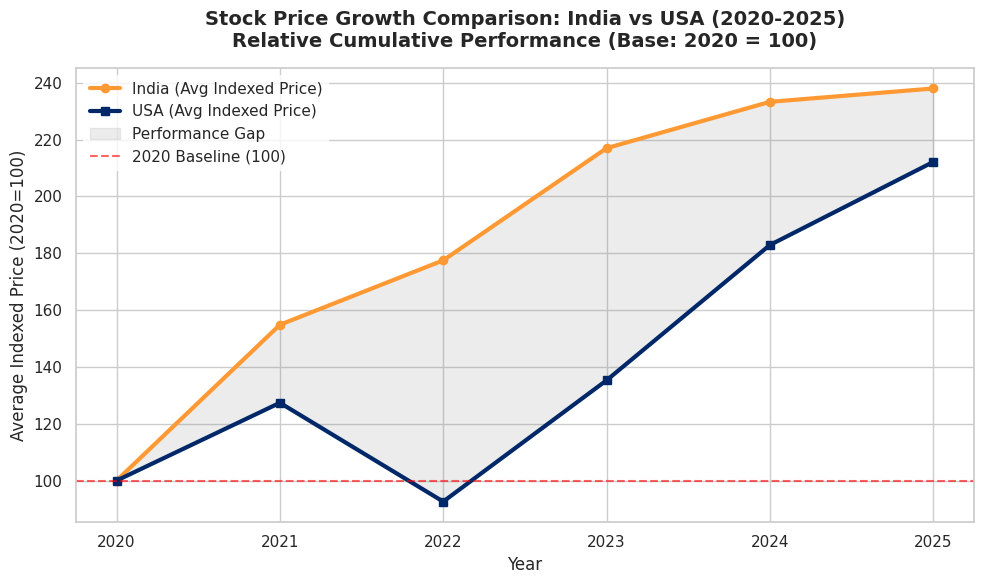

New visualization saved successfully to: /content/India_USA_Analysis_Output/06_usa_vs_india_growth_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pivot the index_country dataframe for easier plotting and gap calculation
pivoted_growth = index_country.pivot(index='Year', columns='Country', values='Index_2020_100')

# Initialize the plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Plot lines with custom styling
plt.plot(pivoted_growth.index, pivoted_growth['India'], marker='o', linewidth=3, color='#FF9933', label='India (Avg Indexed Price)')
plt.plot(pivoted_growth.index, pivoted_growth['USA'], marker='s', linewidth=3, color='#002868', label='USA (Avg Indexed Price)')

# Highlight the performance gap between India and USA
plt.fill_between(pivoted_growth.index, pivoted_growth['India'], pivoted_growth['USA'],
                 color='gray', alpha=0.15, label='Performance Gap')

# Add baseline
plt.axhline(100, color='red', linestyle='--', alpha=0.6, label='2020 Baseline (100)')

# Title and Labels
plt.title('Stock Price Growth Comparison: India vs USA (2020-2025)\nRelative Cumulative Performance (Base: 2020 = 100)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Indexed Price (2020=100)', fontsize=12)
plt.xticks(pivoted_growth.index)

# Formatting Legend & Grid
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()

# Save the plot to the output folder
save_path = OUT / "06_usa_vs_india_growth_comparison.png"
plt.savefig(save_path, dpi=200)
plt.show()

print(f"New visualization saved successfully to: {save_path}")

In [ ]:
# Calculate YoY growth rates for India and USA from the indexed series
pivoted_growth_pct = pivoted_growth.pct_change() * 100

# Compute the Average Annual Growth Rate (AAGR)
aagr = pivoted_growth_pct.mean()

# Also compute Compound Annual Growth Rate (CAGR) from 2020 (value=100) to 2025
n_years = 2025 - 2020
cagr = ((pivoted_growth.loc[2025] / 100) ** (1 / n_years) - 1) * 100

# Prepare summary DataFrame
growth_metrics = pd.DataFrame({
    'AAGR (Average YoY % Change)': aagr,
    'CAGR (2020 to 2025)': cagr
})

display(growth_metrics.round(2))

,AAGR (Average YoY % Change),CAGR (2020 to 2025)
Country,,
India,20.25,18.94
USA,19.47,16.23


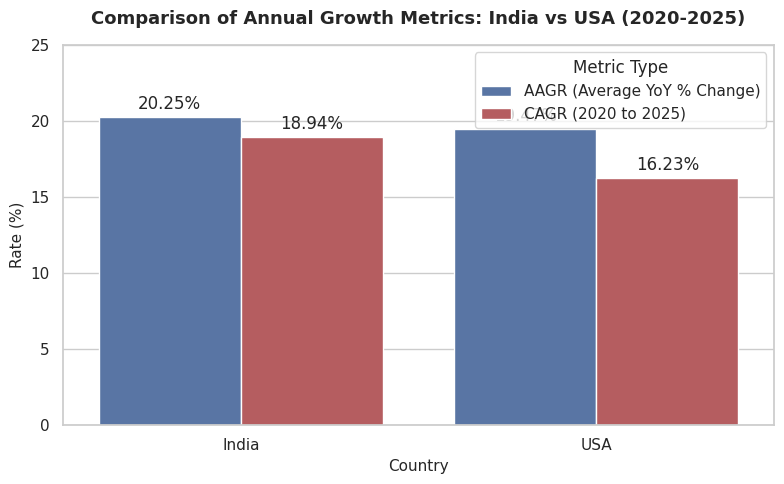

New visualization saved successfully to: /content/India_USA_Analysis_Output/07_aagr_vs_cagr_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reset index of growth_metrics to have 'Country' as a column for easier seaborn plotting
plot_df = growth_metrics.reset_index().melt(
    id_vars='Country',
    value_vars=['AAGR (Average YoY % Change)', 'CAGR (2020 to 2025)'],
    var_name='Metric',
    value_name='Percentage'
)

# Initialize the plot
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Create a grouped bar chart
ax = sns.barplot(
    x='Country',
    y='Percentage',
    hue='Metric',
    data=plot_df,
    palette=['#4C72B0', '#C44E52']
)

# Add value labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

# Title and Labels
plt.title('Comparison of Annual Growth Metrics: India vs USA (2020-2025)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=11)
plt.ylabel('Rate (%)', fontsize=11)
plt.ylim(0, 25)  # Add some space on top for labels

# Customizing Legend & Layout
plt.legend(title='Metric Type', loc='upper right')
plt.tight_layout()

# Save the plot to the output folder
save_path = OUT / "07_aagr_vs_cagr_comparison.png"
plt.savefig(save_path, dpi=200)
plt.show()

print(f"New visualization saved successfully to: {save_path}")

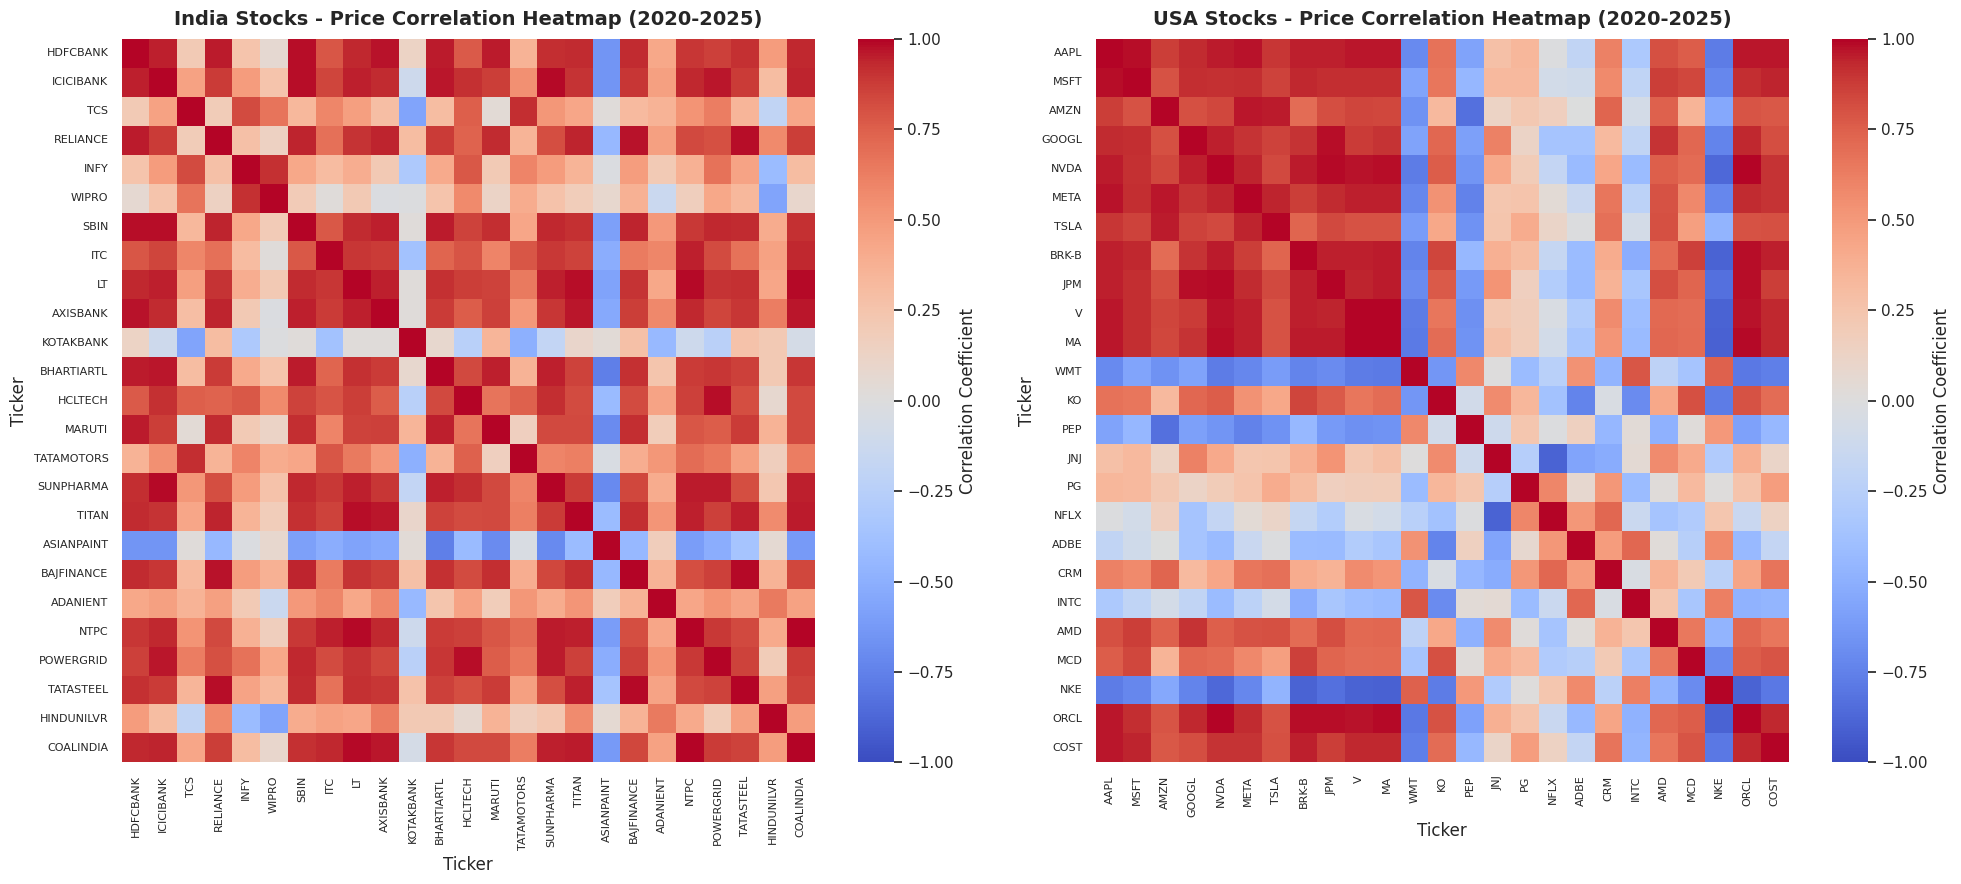

Correlation heatmaps saved successfully to: /content/India_USA_Analysis_Output/08_stock_price_correlation_heatmaps.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter data and pivot to get years as columns and Tickers as rows, separated by Country
india_prices = df[df['Country'] == 'India'].set_index('Ticker')[YEARS].transpose()
usa_prices = df[df['Country'] == 'USA'].set_index('Ticker')[YEARS].transpose()

# Compute correlation matrices among tickers
india_corr = india_prices.corr()
usa_corr = usa_prices.corr()

# Plot side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# India Heatmap
sns.heatmap(
    india_corr,
    ax=axes[0],
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={'label': 'Correlation Coefficient'}
)
axes[0].set_title('India Stocks - Price Correlation Heatmap (2020-2025)', fontsize=14, fontweight='bold', pad=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90, fontsize=8)
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0, fontsize=8)

# USA Heatmap
sns.heatmap(
    usa_corr,
    ax=axes[1],
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={'label': 'Correlation Coefficient'}
)
axes[1].set_title('USA Stocks - Price Correlation Heatmap (2020-2025)', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=90, fontsize=8)
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0, fontsize=8)

plt.tight_layout()

# Save the figure
save_path = OUT / "08_stock_price_correlation_heatmaps.png"
plt.savefig(save_path, dpi=200)
plt.show()

print(f"Correlation heatmaps saved successfully to: {save_path}")

In [ ]:
# Calculate Volatility Drag using the formula: AAGR - CAGR
volatility_drag = aagr - cagr

# Combine metrics into a structured comparison DataFrame
drag_comparison = pd.DataFrame({
    'AAGR (%)': aagr,
    'CAGR (%)': cagr,
    'Volatility Drag (% points)': volatility_drag
})

display(drag_comparison.round(2))

,AAGR (%),CAGR (%),Volatility Drag (% points)
Country,,,
India,20.25,18.94,1.31
USA,19.47,16.23,3.24


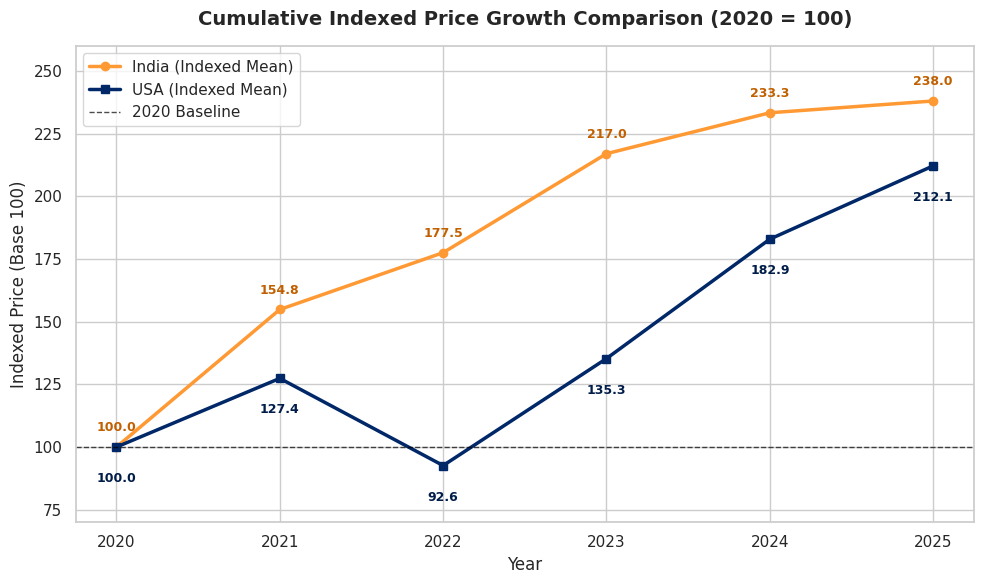

Cumulative comparison line chart saved to: /content/India_USA_Analysis_Output/09_cumulative_indexed_growth_line_chart.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Plot the cumulative indexed trends
plt.plot(pivoted_growth.index, pivoted_growth['India'], marker='o', linewidth=2.5, color='#FF9933', label='India (Indexed Mean)')
plt.plot(pivoted_growth.index, pivoted_growth['USA'], marker='s', linewidth=2.5, color='#002868', label='USA (Indexed Mean)')

# Formatting the chart
plt.title('Cumulative Indexed Price Growth Comparison (2020 = 100)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Indexed Price (Base 100)', fontsize=12)
plt.xticks(pivoted_growth.index)
plt.axhline(100, color='black', linestyle='--', linewidth=1, alpha=0.7, label='2020 Baseline')

# Adding values at each point for clarity
for year in pivoted_growth.index:
    plt.text(year, pivoted_growth.loc[year, 'India'] + 5, f"{pivoted_growth.loc[year, 'India']:.1f}", ha='center', va='bottom', fontsize=9, color='#C16000', fontweight='semibold')
    plt.text(year, pivoted_growth.loc[year, 'USA'] - 10, f"{pivoted_growth.loc[year, 'USA']:.1f}", ha='center', va='top', fontsize=9, color='#001C48', fontweight='semibold')

plt.legend(loc='upper left', frameon=True)
plt.ylim(70, 260)
plt.tight_layout()

# Save cumulative comparison line chart
save_path = OUT / "09_cumulative_indexed_growth_line_chart.png"
plt.savefig(save_path, dpi=200)
plt.show()

print(f"Cumulative comparison line chart saved to: {save_path}")

In [ ]:
import pandas as pd
import numpy as np

outliers_list = []

# Analyze outliers by country
for country, group in ranking.groupby('Country'):
    q1 = group['Change_Percent'].quantile(0.25)
    q3 = group['Change_Percent'].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Outliers are outside [lower_bound, upper_bound]
    outliers = group[(group['Change_Percent'] < lower_bound) | (group['Change_Percent'] > upper_bound)].copy()
    outliers['Outlier_Type'] = np.where(outliers['Change_Percent'] > upper_bound, 'High Outlier', 'Low Outlier')
    outliers['Country_Median_Change'] = group['Change_Percent'].median()
    outliers_list.append(outliers)

all_outliers = pd.concat(outliers_list).sort_values(by='Change_Percent', ascending=False)

print("--- STOCK PERFORMANCE OUTLIERS BY COUNTRY (IQR METHOD) ---")
if not all_outliers.empty:
    display(all_outliers[['Country', 'Company', 'Ticker', 'Change_Percent', 'Country_Median_Change', 'Outlier_Type']].round(2))

    # Save findings
    all_outliers.to_csv(OUT / "stock_performance_outliers.csv", index=False)
    print(f"\nOutliers data saved to: {OUT / 'stock_performance_outliers.csv'}")
else:
    print("No statistical outliers detected using the 1.5x IQR rule.")


--- STOCK PERFORMANCE OUTLIERS BY COUNTRY (IQR METHOD) ---


,Country,Company,Ticker,Change_Percent,Country_Median_Change,Outlier_Type
29,USA,NVIDIA,NVDA,1328.02,50.47,High Outlier



Outliers data saved to: /content/India_USA_Analysis_Output/stock_performance_outliers.csv
